# NLP Lab Assignment 7 — Hindi POS Tagger

**Algorithms:** Naive Bayes word-level tagger; HMM with standard Viterbi, backward Viterbi, and forward–backward posterior decoding.

This notebook follows the assignment PDF. It loads the provided train/dev/test splits, estimates model probabilities from **training data only**, evaluates on development and test sets, reports per-tag F1, and plots per-tag comparisons.

**Expected folder layout:** keep this notebook in the `ASS-7/` directory beside `Hindi-POS-Data/`. The loader searches recursively for train/dev/test files and supports common CoNLL/CoNLL-U, TSV, CSV, and whitespace-separated token-tag formats. If the automatic file/column detection is wrong, set the paths and column names in Section 2 manually.

**Important:** run cells from top to bottom. The test split is used only for final evaluation, not probability estimation or tuning.

## 1. Install/import dependencies

**Process:** use Python's standard library for probability estimation and Viterbi decoding; use pandas for file inspection, scikit-learn for metrics, and matplotlib for plots.

**Formula / dependency:** no model formula is applied in this setup cell. The core algorithms are implemented explicitly rather than delegated to a POS-tagging library.

In [1]:
%pip -q install pandas scikit-learn matplotlib


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


## 2. Locate and inspect train/dev/test files

**Process:** search for filenames containing `train`, `dev`/`valid`, and `test` under `Hindi-POS-Data`. Supported formats are `.conllu`, `.conll`, `.tsv`, `.csv`, `.txt`, and `.data`.

**Data format assumption:** one token per row with a token and POS tag, optionally preceded by sentence IDs or other columns. Blank lines separate sentences in CoNLL-style files. For CSV/TSV, the loader attempts to identify token and tag columns by their names; verify the preview and override settings if needed.

In [2]:
from pathlib import Path
import re, csv, math, json, warnings, collections
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, f1_score, accuracy_score

# Notebook should be in ASS-7 beside Hindi-POS-Data.
ROOT = Path.cwd()
DATA_DIR = ROOT / "Hindi-POS-Data"
if not DATA_DIR.exists():
    # Also support launching the notebook from a parent directory.
    matches = list(ROOT.rglob("Hindi-POS-Data"))
    if matches:
        DATA_DIR = matches[0]
    else:
        raise FileNotFoundError(
            f"Could not find Hindi-POS-Data under {ROOT}. "
            "Place the folder beside this notebook or update DATA_DIR."
        )

SUPPORTED = {".conllu", ".conll", ".tsv", ".csv", ".txt", ".data"}
all_files = [p for p in DATA_DIR.rglob("*") if p.is_file() and p.suffix.lower() in SUPPORTED]
print("Data folder:", DATA_DIR.resolve())
print("Candidate files:")
for p in all_files:
    print(" -", p.relative_to(DATA_DIR))

Data folder: /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/Hindi-POS-Data
Candidate files:
 - hindi-test-pos.txt
 - hindi-dev-pos.txt
 - hindi-train-pos.txt


## 3. Configure file paths and parse the corpus

**Process:** the next cell ranks candidate filenames, then parses the files into `list[list[(word, tag)]]`, where each inner list is one sentence. The final two columns of standard CoNLL-like files are not assumed blindly: the parser uses common column names for CSV/TSV and a common `word ... tag` convention for text files.

**Probability notation:** a sentence is represented as \(S=(w_1,\ldots,w_T)\) with gold tags \(Y=(y_1,\ldots,y_T)\). Keeping sentence boundaries is essential for HMM transition probabilities.

In [3]:
# If auto-detection chooses the wrong files, replace these with exact paths.
TRAIN_PATH = None
DEV_PATH = None
TEST_PATH = None

def choose_file(split):
    if split == "dev":
        keys = ("dev", "valid", "validation")
    else:
        keys = (split,)
    candidates = [p for p in all_files if any(k in p.name.lower() for k in keys)]
    # Prefer files whose names clearly indicate the requested split.
    candidates.sort(key=lambda p: (0 if split in p.name.lower() else 1, len(p.name)))
    if not candidates:
        raise FileNotFoundError(f"No {split} file found in {DATA_DIR}. Set {split.upper()}_PATH manually.")
    return candidates[0]

TRAIN_PATH = Path(TRAIN_PATH) if TRAIN_PATH else choose_file("train")
DEV_PATH = Path(DEV_PATH) if DEV_PATH else choose_file("dev")
TEST_PATH = Path(TEST_PATH) if TEST_PATH else choose_file("test")
print("Train:", TRAIN_PATH)
print("Dev:  ", DEV_PATH)
print("Test: ", TEST_PATH)

def read_corpus(path):
    path = Path(path)
    suffix = path.suffix.lower()
    sentences, current = [], []

    if suffix in {".csv", ".tsv"}:
        sep = "\t" if suffix == ".tsv" else ","
        df = pd.read_csv(path, sep=sep, dtype=str, keep_default_na=False, comment=None)
        if len(df.columns) < 2:
            raise ValueError(f"{path.name}: expected at least two columns, got {df.columns.tolist()}")
        lower = {str(c).strip().lower(): c for c in df.columns}
        word_keys = ["word", "token", "form", "surface", "text"]
        tag_keys = ["tag", "pos", "upos", "xpos", "pos_tag", "label"]
        wc = next((lower[k] for k in word_keys if k in lower), df.columns[0])
        tc = next((lower[k] for k in tag_keys if k in lower), df.columns[-1])
        # If each row is a token, sentence IDs are used to preserve boundaries.
        sid = next((lower[k] for k in ["sentence_id", "sent_id", "sentence", "sent"] if k in lower), None)
        if sid:
            for _, group in df.groupby(sid, sort=False):
                sent = [(str(w).strip(), str(t).strip()) for w,t in zip(group[wc], group[tc])
                        if str(w).strip() and str(t).strip()]
                if sent: sentences.append(sent)
        else:
            # A row may represent one token or a complete sentence with serialized values.
            for _, row in df.iterrows():
                w, t = str(row[wc]).strip(), str(row[tc]).strip()
                if not w or not t: continue
                if " " in w and " " in t:
                    ws, ts = w.split(), t.split()
                    if len(ws) == len(ts):
                        sentences.append(list(zip(ws, ts)))
                    else:
                        sentences.append([(w, t)])
                else:
                    sentences.append([(w, t)])
        print(f"{path.name}: columns={df.columns.tolist()}, word column={wc!r}, tag column={tc!r}")
        return sentences

    # CoNLL-style and whitespace-separated text. Blank lines split sentences.
    with open(path, "r", encoding="utf-8-sig", errors="replace") as f:
        for line in f:
            line = line.strip()
            if not line:
                if current:
                    sentences.append(current); current = []
                continue
            if line.startswith("#"):
                continue
            parts = line.split("\t") if "\t" in line else line.split()
            if len(parts) < 2:
                continue
            # CoNLL-U: ID FORM LEMMA UPOS XPOS ...; otherwise assume first=word,last=tag.
            if suffix in {".conllu", ".conll"} and len(parts) >= 5:
                if parts[0].startswith("#") or "-" in parts[0] or "." in parts[0]:
                    continue
                word = parts[1]
                tag = parts[3] if parts[3] not in {"_", ""} else parts[4]
            else:
                word, tag = parts[0], parts[-1]
            if word and tag and tag != "_":
                current.append((word, tag))
        if current:
            sentences.append(current)
    return sentences

train_sents = read_corpus(TRAIN_PATH)
dev_sents = read_corpus(DEV_PATH)
test_sents = read_corpus(TEST_PATH)

def corpus_summary(name, sents):
    tokens = sum(len(s) for s in sents)
    tags = sorted({tag for s in sents for _, tag in s})
    print(f"{name}: sentences={len(sents):,}, tokens={tokens:,}, unique tags={len(tags)}")
    print("Tags:", tags)
    print("First 2 sentences:", sents[:2])

corpus_summary("TRAIN", train_sents)
corpus_summary("DEV", dev_sents)
corpus_summary("TEST", test_sents)

Train: /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/Hindi-POS-Data/hindi-train-pos.txt
Dev:   /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/Hindi-POS-Data/hindi-dev-pos.txt
Test:  /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/Hindi-POS-Data/hindi-test-pos.txt
TRAIN: sentences=15,087, tokens=325,710, unique tags=24
Tags: ['CC_CCD', 'CC_CCS', 'DM_DMD', 'JJ', 'N_NN', 'N_NNP', 'N_NST', 'PR_PRF', 'PR_PRL', 'PR_PRP', 'PR_PRQ', 'PSP', 'QT_QTC', 'QT_QTF', 'QT_QTO', 'RB', 'RD_PUNC', 'RD_SYM', 'RP_INJ', 'RP_INTF', 'RP_NEG', 'RP_RPD', 'V_VAUX', 'V_VM']
First 2 sentences: [[('यह', 'DM_DMD'), ('एशिया', 'N_NNP'), ('की', 'PSP'), ('सबसे', 'RP_INTF'), ('बड़ी', 'JJ'), ('मस्जिदों', 'N_NN'), ('में', 'PSP'), ('से', 'PSP'), ('एक', 'QT_QTC'), ('है', 'V_VM'), ('।', 'RD_PUNC')], [('इसे', 'PR_PRP'), ('नवाब', 'N_NN'), ('शाहजेहन', 'N_NNP'), ('ने', 'PSP'), ('बनवाया', 'V_VM'), ('था', 'V_VAUX'), ('।', 'RD_PUNC')]]
DEV: sentences=1,866, tokens=40,762, unique tags=24
Tags: ['CC_CCD', 'CC_CCS', 'DM_DMD', 'J

## 4. Validate data and define evaluation helpers

**Process:** remove empty sentences and check that each token has a tag. Tags are taken from the training split for model states. During evaluation, any tag not seen in training is still included in the report and will receive zero predictions unless it can be handled by the data/model.

**Per-tag F1 formula:**

\[
P_c=\frac{TP_c}{TP_c+FP_c},\quad R_c=\frac{TP_c}{TP_c+FN_c},\quad
F1_c=\frac{2P_cR_c}{P_c+R_c}.
\]

If the denominator is zero, scikit-learn reports zero using `zero_division=0`.

In [4]:
def clean_corpus(sents):
    out = []
    for sent in sents:
        pairs = [(str(w), str(t)) for w,t in sent if str(w).strip() and str(t).strip()]
        if pairs: out.append(pairs)
    return out

train_sents, dev_sents, test_sents = map(clean_corpus, [train_sents, dev_sents, test_sents])
TAGS = sorted({tag for sent in train_sents for _, tag in sent})
if not TAGS:
    raise ValueError("No tags were parsed from training data. Check parser settings/columns.")
print("Training tag inventory:", TAGS)
print("Token counts:", {name: sum(len(s) for s in split) for name, split in
                        [("train", train_sents), ("dev", dev_sents), ("test", test_sents)]})

Training tag inventory: ['CC_CCD', 'CC_CCS', 'DM_DMD', 'JJ', 'N_NN', 'N_NNP', 'N_NST', 'PR_PRF', 'PR_PRL', 'PR_PRP', 'PR_PRQ', 'PSP', 'QT_QTC', 'QT_QTF', 'QT_QTO', 'RB', 'RD_PUNC', 'RD_SYM', 'RP_INJ', 'RP_INTF', 'RP_NEG', 'RP_RPD', 'V_VAUX', 'V_VM']
Token counts: {'train': 325710, 'dev': 40762, 'test': 41415}


## 5. Naive Bayes tagger — feature construction

**Required features from the assignment:**
1. Word length: `MORE` if character length \(>4\), otherwise `LESS`.
2. Actual word.
3. Previous word.
4. Next word.
5. Previous tag.

**Process:** train a categorical Naive Bayes model on token-level feature dictionaries. The previous tag is the gold previous tag while training; at inference time it is the previously predicted tag (greedy left-to-right decoding). Sentence-boundary markers `<BOS>` and `<EOS>` are used for missing neighbors.

**Naive Bayes formula:**

\[
\hat y=\arg\max_y P(y)\prod_j P(f_j\mid y).
\]

Categorical feature likelihoods use Laplace smoothing:

\[
P(f_j=v\mid y)=\frac{N(y,f_j=v)+\alpha}{N(y)+\alpha |V_j|}.
\]

`DictVectorizer` one-hot encodes categorical values; `MultinomialNB` estimates the smoothed probabilities.

In [5]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.naive_bayes import MultinomialNB

BOS, EOS = "<BOS>", "<EOS>"

def nb_features(words, i, previous_tag):
    word = words[i]
    return {
        "length": "MORE" if len(word) > 4 else "LESS",
        "word": word,
        "prev_word": words[i-1] if i > 0 else BOS,
        "next_word": words[i+1] if i+1 < len(words) else EOS,
        "prev_tag": previous_tag if previous_tag is not None else BOS,
    }

X_nb, y_nb = [], []
for sent in train_sents:
    words = [w for w,_ in sent]
    tags = [t for _,t in sent]
    for i, tag in enumerate(tags):
        X_nb.append(nb_features(words, i, tags[i-1] if i else None))
        y_nb.append(tag)

nb_vectorizer = DictVectorizer(sparse=True)
X_nb_vec = nb_vectorizer.fit_transform(X_nb)
nb_model = MultinomialNB(alpha=1.0)
nb_model.fit(X_nb_vec, y_nb)
print("Training token instances:", len(y_nb))
print("Feature vocabulary size:", len(nb_vectorizer.feature_names_))

Training token instances: 325710
Feature vocabulary size: 54604


## 6. Predict with Naive Bayes

**Process:** decode each sentence from left to right. At position \(i\), the feature `prev_tag` uses the predicted tag at position \(i-1\), avoiding use of the gold answer during inference.

**Boundary condition:** at the first token, previous word and previous tag are `<BOS>`; at the final token, next word is `<EOS>`.

In [6]:
def predict_nb_sentence(sent):
    words = [w for w,_ in sent]
    predictions = []
    previous_tag = None
    for i in range(len(words)):
        feats = nb_features(words, i, previous_tag)
        pred = nb_model.predict(nb_vectorizer.transform([feats]))[0]
        predictions.append(pred)
        previous_tag = pred
    return predictions

def predict_nb(sents):
    return [predict_nb_sentence(sent) for sent in sents]

nb_dev_pred = predict_nb(dev_sents)
nb_test_pred = predict_nb(test_sents)
print("Example gold:", dev_sents[0][:12] if dev_sents else "No dev sentences")
print("Example NB:  ", list(zip([w for w,_ in dev_sents[0]], nb_dev_pred[0]))[:12] if dev_sents else "No dev sentences")

Example gold: [('प्राचीनकाल', 'N_NN'), ('के', 'PSP'), ('सोलह', 'QT_QTC'), ('महाजनपदों', 'N_NN'), ('में', 'PSP'), ('से', 'PSP'), ('एक', 'QT_QTC'), ("'", 'RD_PUNC'), ('कुशीनारा', 'N_NNP'), ("'", 'RD_PUNC'), ('(', 'RD_SYM'), ('आज', 'N_NN')]
Example NB:   [('प्राचीनकाल', np.str_('N_NNP')), ('के', np.str_('PSP')), ('सोलह', np.str_('N_NN')), ('महाजनपदों', np.str_('N_NN')), ('में', np.str_('PSP')), ('से', np.str_('PSP')), ('एक', np.str_('QT_QTC')), ("'", np.str_('N_NN')), ('कुशीनारा', np.str_('N_NNP')), ("'", np.str_('RD_PUNC')), ('(', np.str_('PSP')), ('आज', np.str_('N_NN'))]


## 7. HMM probability estimation

**Process:** estimate initial, transition, and emission probabilities from training sentences.

- Initial: \(P(y_1)\)
- Transition: \(P(y_t\mid y_{t-1})\)
- Emission: \(P(w_t\mid y_t)\)

**Maximum-likelihood counts with additive smoothing:**

\[
P(y_1)=\frac{C_{start}(y_1)+\alpha}{N_{sent}+\alpha K}
\]

\[
P(y'\mid y)=\frac{C(y,y')+\alpha}{C(y)+\alpha K}
\]

\[
P(w\mid y)=\frac{C(y,w)+\alpha}{C(y)+\alpha (V+1)}.
\]

Here \(K\) is the number of POS tags and \(V\) is the training vocabulary size. The extra emission bucket provides an unknown-word fallback. We work in log space to avoid numerical underflow.

In [7]:
from collections import Counter, defaultdict

ALPHA = 0.1
tag_counts = Counter()
start_counts = Counter()
trans_counts = defaultdict(Counter)
emit_counts = defaultdict(Counter)
vocab = set()

for sent in train_sents:
    words = [w for w,_ in sent]
    tags = [t for _,t in sent]
    if not tags: continue
    start_counts[tags[0]] += 1
    for i, (word, tag) in enumerate(sent):
        tag_counts[tag] += 1
        emit_counts[tag][word] += 1
        vocab.add(word)
        if i > 0:
            trans_counts[tags[i-1]][tag] += 1

K = len(TAGS)
V = len(vocab)
N_SENT = len(train_sents)

def log_initial(tag):
    return math.log((start_counts[tag] + ALPHA) / (N_SENT + ALPHA*K))

def log_transition(prev_tag, tag):
    return math.log((trans_counts[prev_tag][tag] + ALPHA) /
                    (tag_counts[prev_tag] + ALPHA*K))

def log_emission(tag, word):
    # Unknown words share one smoothed unseen-word bucket.
    return math.log((emit_counts[tag][word] + ALPHA) /
                    (tag_counts[tag] + ALPHA*(V+1)))

print(f"Tags K={K}, vocabulary V={V:,}, training sentences={N_SENT:,}, alpha={ALPHA}")
print("Example log initial probabilities:", {t: round(log_initial(t), 4) for t in TAGS[:5]})

Tags K=24, vocabulary V=18,279, training sentences=15,087, alpha=0.1
Example log initial probabilities: {'CC_CCD': -3.3318, 'CC_CCS': -3.8073, 'DM_DMD': -2.5873, 'JJ': -2.7372, 'N_NN': -1.5656}


## 8. HMM standard forward Viterbi (left-to-right dynamic programming)

**Process:** choose the single most probable tag sequence. Let \(V_t(s)\) be the best log-probability of a path ending in tag \(s\) at position \(t\).

**Recurrence:**

\[
V_1(s)=\log P(s)+\log P(w_1\mid s)
\]

\[
V_t(s)=\max_{r\in Tags}\left[V_{t-1}(r)+\log P(s\mid r)\right]
+\log P(w_t\mid s).
\]

Store the maximizing predecessor (backpointer) and backtrack from the best final tag.

In [8]:
def viterbi_forward(words):
    if not words: return []
    dp = []
    back = []
    dp0 = {tag: log_initial(tag) + log_emission(tag, words[0]) for tag in TAGS}
    dp.append(dp0)
    back.append({tag: None for tag in TAGS})
    for i in range(1, len(words)):
        cur, bp = {}, {}
        for tag in TAGS:
            candidates = [(dp[i-1][prev] + log_transition(prev, tag), prev) for prev in TAGS]
            best_score, best_prev = max(candidates)
            cur[tag] = best_score + log_emission(tag, words[i])
            bp[tag] = best_prev
        dp.append(cur); back.append(bp)
    last = max(TAGS, key=lambda tag: dp[-1][tag])
    path = [last]
    for i in range(len(words)-1, 0, -1):
        path.append(back[i][path[-1]])
    return list(reversed(path))

def predict_hmm_forward(sents):
    return [viterbi_forward([w for w,_ in sent]) for sent in sents]

fw_dev_pred = predict_hmm_forward(dev_sents)
fw_test_pred = predict_hmm_forward(test_sents)
print("Forward Viterbi example:", list(zip([w for w,_ in dev_sents[0]], fw_dev_pred[0]))[:12] if dev_sents else "No dev sentences")

Forward Viterbi example: [('प्राचीनकाल', 'N_NNP'), ('के', 'PSP'), ('सोलह', 'QT_QTC'), ('महाजनपदों', 'N_NN'), ('में', 'PSP'), ('से', 'PSP'), ('एक', 'QT_QTC'), ("'", 'RD_PUNC'), ('कुशीनारा', 'N_NNP'), ("'", 'RD_PUNC'), ('(', 'RD_SYM'), ('आज', 'N_NN')]


## 9. HMM backward Viterbi

**Process:** dynamic programming starts at the right edge and stores the best suffix score conditioned on the tag at the current position. The best complete path is reconstructed from the best start tag and right-to-left choices.

**Recurrence:** define \(B_t(s)\) as the best log score for positions \(t+1,\ldots,T\), given \(y_t=s\).

\[
B_T(s)=0
\]

\[
B_t(s)=\max_{q\in Tags}\left[
\log P(q\mid s)+\log P(w_{t+1}\mid q)+B_{t+1}(q)
\right].
\]

Choose \(y_1=\arg\max_s[\log P(s)+\log P(w_1\mid s)+B_1(s)]\), then greedily follow the maximizing suffix choices. This is a reverse dynamic-programming implementation of the same best-path objective as standard Viterbi.

In [9]:
def viterbi_backward(words):
    T = len(words)
    if T == 0: return []
    # beta[t][tag] is the best suffix score after position t, given tag at t.
    beta = [{tag: 0.0 for tag in TAGS} for _ in range(T)]
    next_choice = [{} for _ in range(T)]
    for i in range(T-2, -1, -1):
        for tag in TAGS:
            candidates = [
                log_transition(tag, nxt) + log_emission(nxt, words[i+1]) + beta[i+1][nxt]
                for nxt in TAGS
            ]
            best_idx = int(np.argmax(candidates))
            beta[i][tag] = candidates[best_idx]
            next_choice[i][tag] = TAGS[best_idx]
    first_scores = {
        tag: log_initial(tag) + log_emission(tag, words[0]) + beta[0][tag]
        for tag in TAGS
    }
    first = max(TAGS, key=lambda tag: first_scores[tag])
    path = [first]
    for i in range(T-1):
        path.append(next_choice[i][path[-1]])
    return path

def predict_hmm_backward(sents):
    return [viterbi_backward([w for w,_ in sent]) for sent in sents]

bw_dev_pred = predict_hmm_backward(dev_sents)
bw_test_pred = predict_hmm_backward(test_sents)
print("Backward Viterbi example:", list(zip([w for w,_ in dev_sents[0]], bw_dev_pred[0]))[:12] if dev_sents else "No dev sentences")
print("Forward/backward agree on dev tokens:",
      sum(a==b for x,y in zip(fw_dev_pred,bw_dev_pred) for a,b in zip(x,y)),
      "/", sum(map(len, fw_dev_pred)))

Backward Viterbi example: [('प्राचीनकाल', 'N_NNP'), ('के', 'PSP'), ('सोलह', 'QT_QTC'), ('महाजनपदों', 'N_NN'), ('में', 'PSP'), ('से', 'PSP'), ('एक', 'QT_QTC'), ("'", 'RD_PUNC'), ('कुशीनारा', 'N_NNP'), ("'", 'RD_PUNC'), ('(', 'RD_SYM'), ('आज', 'N_NN')]
Forward/backward agree on dev tokens: 40762 / 40762


## 10. HMM forward–backward posterior decoding

**Process:** unlike Viterbi's maximum-probability *whole sequence*, forward–backward computes the posterior probability of each tag at each position and picks the highest marginal tag independently at each position.

**Forward recurrence:**

\[
\alpha_1(s)=P(s)P(w_1\mid s),\quad
\alpha_t(s)=P(w_t\mid s)\sum_r \alpha_{t-1}(r)P(s\mid r).
\]

**Backward recurrence:**

\[
\beta_T(s)=1,\quad
\beta_t(s)=\sum_q P(q\mid s)P(w_{t+1}\mid q)\beta_{t+1}(q).
\]

**Posterior marginal:**

\[
P(y_t=s\mid w_{1:T})=
\frac{\alpha_t(s)\beta_t(s)}
{\sum_r\alpha_t(r)\beta_t(r)}.
\]

The implementation uses log-sum-exp for numerical stability. Marginal decoding can sometimes produce a tag sequence that is not the single most probable full sequence.

In [10]:
def logsumexp(values):
    m = max(values)
    if m == -math.inf: return m
    return m + math.log(sum(math.exp(v-m) for v in values))

def forward_backward_decode(words):
    T = len(words)
    if T == 0: return []
    # Log alpha
    alpha = [{tag: log_initial(tag) + log_emission(tag, words[0]) for tag in TAGS}]
    for i in range(1, T):
        row = {}
        for tag in TAGS:
            row[tag] = log_emission(tag, words[i]) + logsumexp([
                alpha[i-1][prev] + log_transition(prev, tag) for prev in TAGS
            ])
        alpha.append(row)
    # Log beta
    beta = [dict() for _ in range(T)]
    beta[T-1] = {tag: 0.0 for tag in TAGS}
    for i in range(T-2, -1, -1):
        row = {}
        for tag in TAGS:
            row[tag] = logsumexp([
                log_transition(tag, nxt) + log_emission(nxt, words[i+1]) + beta[i+1][nxt]
                for nxt in TAGS
            ])
        beta[i] = row
    # Argmax marginal posterior at each token.
    return [max(TAGS, key=lambda tag: alpha[i][tag] + beta[i][tag]) for i in range(T)]

def predict_hmm_fb(sents):
    return [forward_backward_decode([w for w,_ in sent]) for sent in sents]

fb_dev_pred = predict_hmm_fb(dev_sents)
fb_test_pred = predict_hmm_fb(test_sents)
print("Forward-backward example:", list(zip([w for w,_ in dev_sents[0]], fb_dev_pred[0]))[:12] if dev_sents else "No dev sentences")

Forward-backward example: [('प्राचीनकाल', 'N_NNP'), ('के', 'PSP'), ('सोलह', 'QT_QTC'), ('महाजनपदों', 'N_NN'), ('में', 'PSP'), ('से', 'PSP'), ('एक', 'QT_QTC'), ("'", 'RD_PUNC'), ('कुशीनारा', 'N_NNP'), ("'", 'RD_PUNC'), ('(', 'RD_SYM'), ('आज', 'N_NN')]


## 11. Evaluate each algorithm on dev and test

**Process:** flatten gold and predicted tags across tokens, while retaining sentence boundaries for decoding. Compute precision, recall, F1, and support for every tag. Labels are the union of training tags and tags observed in the evaluated gold split, so unseen gold tags are not silently omitted.

**Micro accuracy:** \(	ext{Accuracy}=\frac{\text{correctly predicted tokens}}{\text{all tokens}}\).

**F1 comparison:** the assignment asks for per-tag F1; we also record macro F1 and token accuracy as overall summaries.

In [11]:
def flatten_gold(sents):
    return [tag for sent in sents for _,tag in sent]

def flatten_pred(preds):
    return [tag for sent in preds for tag in sent]

def evaluate(name, sents, preds):
    gold = flatten_gold(sents)
    pred = flatten_pred(preds)
    if len(gold) != len(pred):
        raise ValueError(f"{name}: gold/pred length mismatch {len(gold)} vs {len(pred)}")
    labels = sorted(set(TAGS) | set(gold) | set(pred))
    report = classification_report(gold, pred, labels=labels, output_dict=True, zero_division=0)
    rows = []
    for tag in labels:
        r = report.get(tag, {})
        rows.append({"algorithm": name, "tag": tag, "precision": r.get("precision", 0.0),
                     "recall": r.get("recall", 0.0), "f1": r.get("f1-score", 0.0),
                     "support": r.get("support", 0)})
    summary = {"algorithm": name, "accuracy": accuracy_score(gold, pred) if gold else 0.0,
               "macro_f1": f1_score(gold, pred, labels=labels, average="macro", zero_division=0) if gold else 0.0,
               "weighted_f1": f1_score(gold, pred, labels=labels, average="weighted", zero_division=0) if gold else 0.0,
               "tokens": len(gold)}
    return pd.DataFrame(rows), summary

algorithms = {
    "Naive Bayes": (nb_dev_pred, nb_test_pred),
    "Forward Viterbi": (fw_dev_pred, fw_test_pred),
    "Backward Viterbi": (bw_dev_pred, bw_test_pred),
    "Forward-Backward": (fb_dev_pred, fb_test_pred),
}
dev_tables, test_tables, dev_summaries, test_summaries = [], [], [], []
for name, (dp, tp) in algorithms.items():
    dtab, dsum = evaluate(name, dev_sents, dp)
    ttab, tsum = evaluate(name, test_sents, tp)
    dev_tables.append(dtab); test_tables.append(ttab)
    dev_summaries.append(dsum); test_summaries.append(tsum)

dev_metrics = pd.concat(dev_tables, ignore_index=True)
test_metrics = pd.concat(test_tables, ignore_index=True)
dev_summary = pd.DataFrame(dev_summaries).sort_values("macro_f1", ascending=False)
test_summary = pd.DataFrame(test_summaries).sort_values("macro_f1", ascending=False)

print("DEVELOPMENT SUMMARY")
display(dev_summary.style.format({"accuracy":"{:.4f}", "macro_f1":"{:.4f}", "weighted_f1":"{:.4f}"}))
print("TEST SUMMARY")
display(test_summary.style.format({"accuracy":"{:.4f}", "macro_f1":"{:.4f}", "weighted_f1":"{:.4f}"}))

DEVELOPMENT SUMMARY


,algorithm,accuracy,macro_f1,weighted_f1,tokens
3,Forward-Backward,0.9308,0.9082,0.9303,40762
1,Forward Viterbi,0.9305,0.9071,0.9302,40762
2,Backward Viterbi,0.9305,0.9071,0.9302,40762
0,Naive Bayes,0.9007,0.6617,0.8956,40762


TEST SUMMARY


,algorithm,accuracy,macro_f1,weighted_f1,tokens
1,Forward Viterbi,0.9285,0.8674,0.9283,41415
2,Backward Viterbi,0.9285,0.8674,0.9283,41415
3,Forward-Backward,0.9295,0.8635,0.9292,41415
0,Naive Bayes,0.9006,0.6624,0.8954,41415


## 12. Per-tag F1 tables

**Process:** display per-tag F1 for development and test for all four algorithms. The support column indicates how many gold tokens of each tag occur in that split; low-support tags can have unstable F1.

In [12]:
print("Per-tag development F1")
display(dev_metrics.pivot(index="tag", columns="algorithm", values="f1").fillna(0).round(4))
print("Per-tag test F1")
display(test_metrics.pivot(index="tag", columns="algorithm", values="f1").fillna(0).round(4))

Per-tag development F1


algorithm,Backward Viterbi,Forward Viterbi,Forward-Backward,Naive Bayes
tag,,,,
CC_CCD,0.9607,0.9607,0.9657,0.9533
CC_CCS,0.9554,0.9554,0.9683,0.9418
DM_DMD,0.8959,0.8959,0.9147,0.8126
JJ,0.8870,0.8870,0.8873,0.8356
N_NN,0.9147,0.9147,0.9157,0.8864
N_NNP,0.8384,0.8384,0.8339,0.8216
N_NST,0.9436,0.9436,0.9136,0.9171
PR_PRF,0.9935,0.9935,0.9838,0.5385
PR_PRL,0.8596,0.8596,0.7984,0.1724


Per-tag test F1


algorithm,Backward Viterbi,Forward Viterbi,Forward-Backward,Naive Bayes
tag,,,,
CC_CCD,0.9507,0.9507,0.9611,0.9640
CC_CCS,0.9526,0.9526,0.9652,0.9566
DM_DMD,0.8955,0.8955,0.9135,0.8618
JJ,0.8992,0.8992,0.9007,0.8560
N_NN,0.9072,0.9072,0.9087,0.8794
N_NNP,0.8411,0.8411,0.8399,0.8251
N_NST,0.9309,0.9309,0.9095,0.9341
PR_PRF,0.9967,0.9967,0.9934,0.5340
PR_PRL,0.8350,0.8350,0.7489,0.1616


## 13. Plot per-tag F1 comparisons

**Process:** create separate grouped bar charts for dev and test. Each group is a POS tag and each bar is an algorithm's F1-score.

**Interpretation:** compare tags with consistently high F1 against low-performing tags. Rare tags may be harder because their transition/emission counts are small. Do not claim one model is better without checking the displayed metrics.

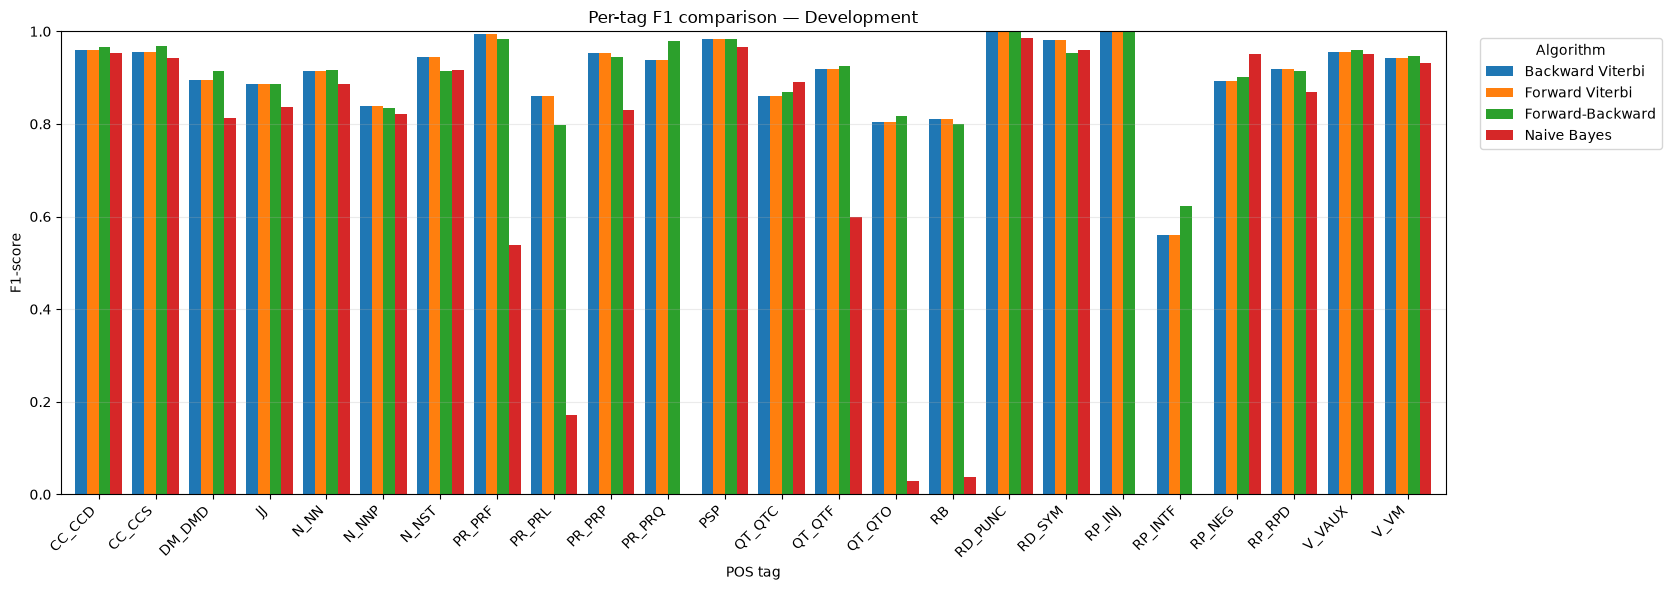

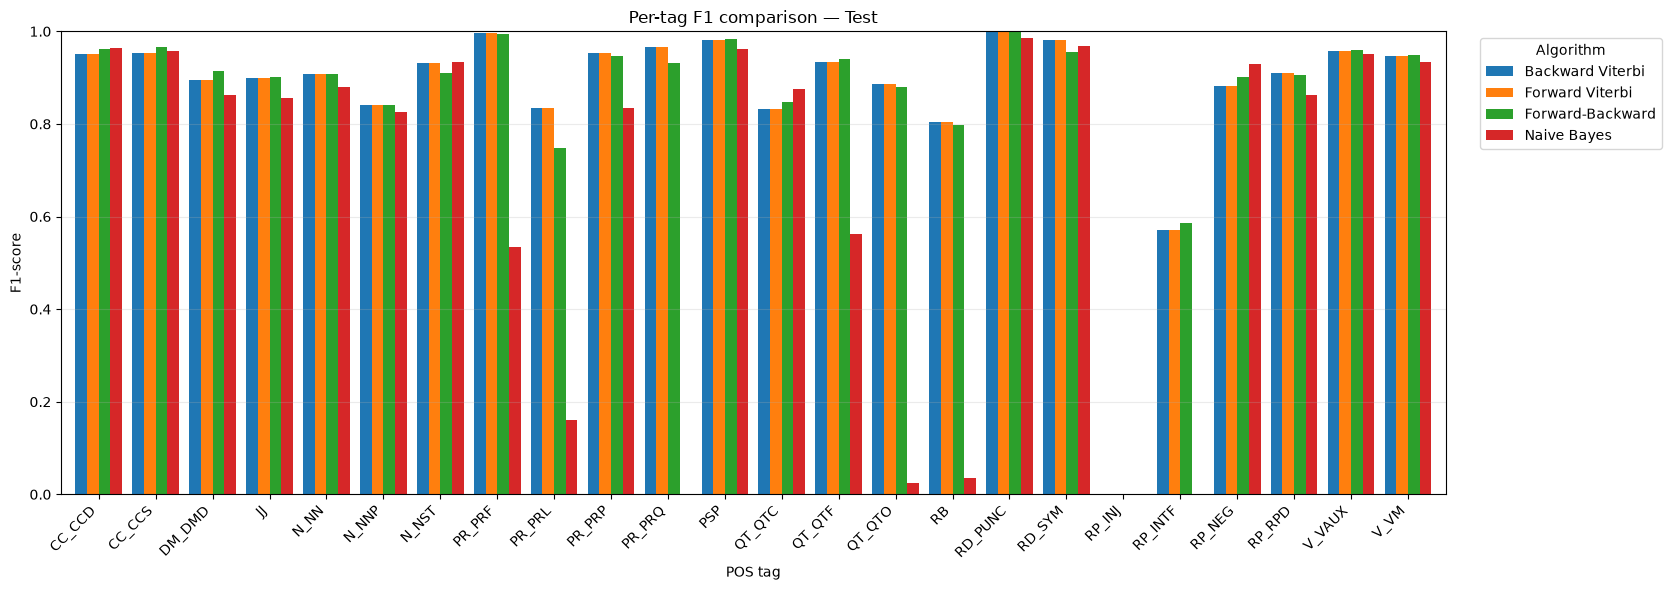

In [13]:
def plot_tag_f1(metrics, split_name):
    pivot = metrics.pivot(index="tag", columns="algorithm", values="f1").fillna(0)
    ax = pivot.plot(kind="bar", figsize=(max(12, len(pivot)*0.7), 6), width=0.82)
    ax.set_title(f"Per-tag F1 comparison — {split_name}")
    ax.set_xlabel("POS tag")
    ax.set_ylabel("F1-score")
    ax.set_ylim(0, 1)
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=45, ha="right")
    plt.legend(title="Algorithm", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()

plot_tag_f1(dev_metrics, "Development")
plot_tag_f1(test_metrics, "Test")

## 14. Plot overall metrics

**Process:** compare token accuracy, macro F1, and weighted F1 for each algorithm on both dev and test.

**Formula distinction:** macro F1 is the unweighted mean of per-tag F1; weighted F1 weights each tag's F1 by its gold support. Macro F1 is more sensitive to low-frequency tags, while weighted F1 reflects the label distribution.

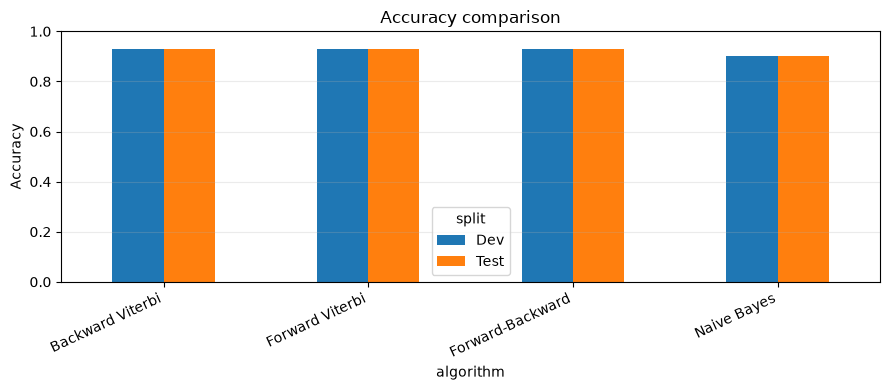

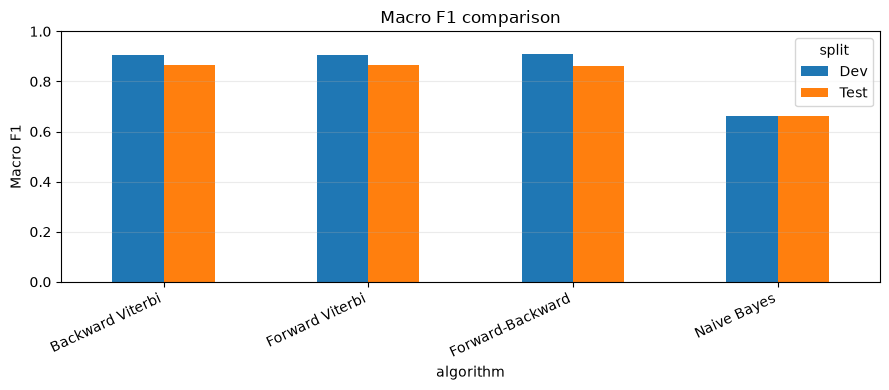

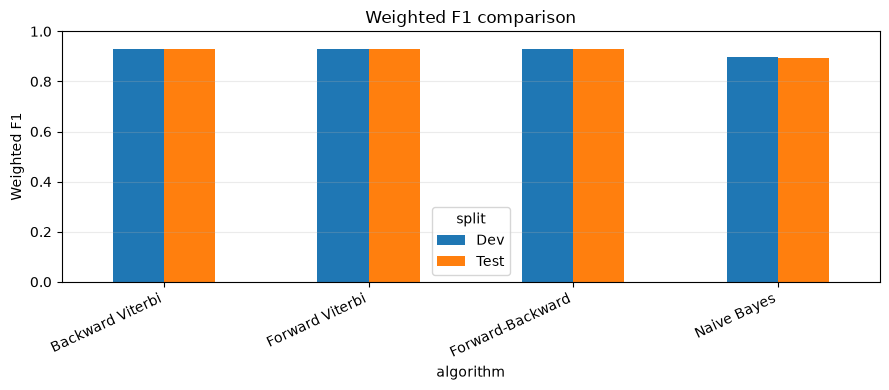

In [14]:
overall = pd.concat([
    dev_summary.assign(split="Dev"),
    test_summary.assign(split="Test")
], ignore_index=True)
for metric in ["accuracy", "macro_f1", "weighted_f1"]:
    p = overall.pivot(index="algorithm", columns="split", values=metric)
    ax = p.plot(kind="bar", figsize=(9, 4), ylim=(0,1), title=f"{metric.replace('_',' ').title()} comparison")
    ax.set_ylabel(metric.replace("_"," ").title())
    ax.grid(axis="y", alpha=0.25)
    plt.xticks(rotation=25, ha="right")
    plt.tight_layout()
    plt.show()

## 15. Error analysis

**Process:** inspect example tokens where models disagree with the gold tag. This helps identify ambiguous words, rare tags, tokenization problems, and parsing mistakes.

**Caution:** a POS tagger can only be evaluated correctly if the dataset was parsed into the right token/tag columns and sentence boundaries. If examples look like the tag has become a word, revisit Section 3 and explicitly set the parser's columns/format.

In [15]:
def show_errors(sents, preds, limit=30):
    errors = []
    for si, (sent, pred_sent) in enumerate(zip(sents, preds)):
        for ti, ((word, gold), pred) in enumerate(zip(sent, pred_sent)):
            if gold != pred:
                errors.append({"sentence_index": si, "token_index": ti, "word": word,
                               "gold": gold, "predicted": pred})
                if len(errors) >= limit:
                    return pd.DataFrame(errors)
    return pd.DataFrame(errors)

print("Naive Bayes errors on dev:")
display(show_errors(dev_sents, nb_dev_pred))
print("Forward Viterbi errors on dev:")
display(show_errors(dev_sents, fw_dev_pred))

Naive Bayes errors on dev:


,sentence_index,token_index,word,gold,predicted
0,0,0,प्राचीनकाल,N_NN,N_NNP
1,0,2,सोलह,QT_QTC,N_NN
2,0,7,',RD_PUNC,N_NN
3,0,10,(,RD_SYM,PSP
4,0,13,कुशीनगर,N_NNP,N_NN
5,0,15,अपने,PR_PRF,PSP
6,0,16,प्राचीन,JJ,N_NN
7,0,18,वैभवशाली,JJ,N_NNP
8,0,20,धर्म,N_NN,N_NNP
9,1,1,काल,N_NNP,N_NN


Forward Viterbi errors on dev:


,sentence_index,token_index,word,gold,predicted
0,0,0,प्राचीनकाल,N_NN,N_NNP
1,0,18,वैभवशाली,JJ,N_NNP
2,0,20,धर्म,N_NN,N_NNP
3,1,1,काल,N_NNP,N_NN
4,1,7,कुश,N_NNP,N_NN
5,1,10,कुशावती,N_NNP,N_NN
6,1,12,483,N_NNP,N_NST
7,1,13,ईसा,N_NNP,RP_RPD
8,1,14,पूर्व,N_NNP,JJ
9,2,0,मल्‍लों,N_NN,N_NNP


## 16. Save evaluation outputs

**Process:** save per-tag metrics, overall summaries, and token-level test predictions to a `results/` directory beside the notebook. These files make the results easy to include in the assignment report.

**Prediction output columns:** `sentence_index`, `token_index`, `word`, `gold_tag`, plus one predicted tag column per algorithm.

In [16]:
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)
dev_metrics.to_csv(RESULTS_DIR / "dev_per_tag_f1.csv", index=False)
test_metrics.to_csv(RESULTS_DIR / "test_per_tag_f1.csv", index=False)
dev_summary.to_csv(RESULTS_DIR / "dev_summary.csv", index=False)
test_summary.to_csv(RESULTS_DIR / "test_summary.csv", index=False)

prediction_rows = []
for si, sent in enumerate(test_sents):
    for ti, (word, gold) in enumerate(sent):
        row = {"sentence_index": si, "token_index": ti, "word": word, "gold_tag": gold}
        for name, (_, test_pred) in algorithms.items():
            row[name.lower().replace("-", "_").replace(" ", "_")] = test_pred[si][ti]
        prediction_rows.append(row)
pd.DataFrame(prediction_rows).to_csv(RESULTS_DIR / "test_predictions.csv", index=False)
print("Saved files:")
for p in sorted(RESULTS_DIR.iterdir()):
    print(" -", p.resolve())

Saved files:
 - /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/results/dev_per_tag_f1.csv
 - /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/results/dev_summary.csv
 - /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/results/test_per_tag_f1.csv
 - /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/results/test_predictions.csv
 - /home/komal-sai-jakka/ACADEMICS/5th_sem/NLP/ASS-7/results/test_summary.csv


## 17. Comparison and conclusion template

**How to write the result:** use the actual values from the summary tables generated above; do not fill in results before running the notebook on the supplied files.

- **Naive Bayes:** token-level classifier using word context and a previous-tag feature. Its decoding is greedy and can propagate earlier errors.
- **Forward Viterbi:** finds the most probable complete tag sequence using left-to-right dynamic programming.
- **Backward Viterbi:** solves the same best-sequence objective with suffix-oriented dynamic programming; its sequence should generally agree with standard Viterbi when implemented with identical probabilities and tie handling.
- **Forward–backward:** uses posterior marginal probabilities per position and may differ from Viterbi because it maximizes each token's marginal, not the joint sequence probability.

**Report checklist**
1. State train/dev/test sentence and token counts and the tag inventory.
2. Report dev and test accuracy, macro F1, weighted F1, and per-tag F1.
3. Include the per-tag F1 charts.
4. Discuss tags with the best and worst F1 and consider their support.
5. Mention smoothing (`alpha = 0.1` for HMM and `alpha = 1.0` for Naive Bayes) and any file-format/parser corrections.
6. Confirm that test data was not used to estimate probabilities.

**Limitations:** the HMM uses first-order tag transitions and word emissions, so unknown words are handled only through a shared smoothed fallback. The Naive Bayes model's previous-tag feature is trained with gold previous tags but inferred using predicted previous tags, which creates train/inference mismatch.